# 05 · Event study and time series

The announcement (`config.ANNOUNCE_UTC`, Nov 9 10:30 ET) is treated as the event. Two levels:

1. **By video publish period** (before / announcement / after). Different videos, so the topic changes too. The cleanest pair is 1 vs 4: the same weekly CFP rankings show, a week apart. To give every video the same exposure, this level uses only comments posted in the **first 48 hours after upload**.
The main score is **VADER + sports words** (chosen with the hand labels in notebook 04); standard VADER and TextBlob are sensitivity checks.

2. **By comment timestamp within a video** (the main analysis). For videos published before the announcement, comments are split at the announcement time. Same video and host, only the news changes. `ANNOUNCE_UTC_ALT` (10:30 CT) is the sensitivity check.

**Main caveat:** comments posted after the announcement on an older video are also *late* comments, written by people who found the video days later. A regression that controls for comment age (log hours since upload), reply status and video separates the two in part.

**Second caveat:** expansion leaked on Oct 15–16, so "before" is not news-free. Notebook 04 showed that pre-announcement comments already discussed expansion.

In [1]:
import sys
import re
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import config

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 110)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

CREATOR_NAMES = {"pate": "Josh Pate", "crain_cone": "Crain & Cone"}
CREATOR_COLORS = {"Josh Pate": "#1f5fa8", "Crain & Cone": "#d9822b"}
PERIOD_ORDER = ["before", "announcement", "after"]

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv(config.DATA_DIR / "comments_scored.csv", keep_default_na=False,
                 parse_dates=["published_utc", "updated_utc", "video_published_utc"])
df["country"] = df["country"].replace("", np.nan)
df["creator_name"] = df["creator"].map(CREATOR_NAMES)
df.shape

(9456, 37)

In [3]:
# Main score: VADER with the sports word list (chosen with the hand labels in notebook 04).
SCORE, LABEL, SCORE_NAME = "vader_sports_compound", "vader_sports_label", "VADER + sports"

from scipy import stats
import statsmodels.formula.api as smf

def compare(a, b):
    """Welch t-test, Mann-Whitney U and Cohen's d for two score samples."""
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    t, p_t = stats.ttest_ind(b, a, equal_var=False)
    _, p_u = stats.mannwhitneyu(b, a, alternative="two-sided")
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return pd.Series({"n_a": len(a), "n_b": len(b), "mean_a": a.mean(), "mean_b": b.mean(),
                      "diff": b.mean() - a.mean(), "cohens_d": (b.mean() - a.mean()) / pooled,
                      "p_welch": p_t, "p_mannwhitney": p_u})

def neg_share(s):
    return (s == "negative").mean()

In [4]:
WINDOW_H = 48
LABEL_ORDER = ["negative", "neutral", "positive"]

## Level 1: by video period (first 48 hours of each video)

In [5]:
first48 = df[df["hours_since_upload"] <= WINDOW_H].copy()
print(f"{len(first48):,} of {len(df):,} comments fall in the first {WINDOW_H} h of their video")

level1 = (first48.groupby(["creator_name", "period"])
          .agg(n=(SCORE, "size"), mean_score=(SCORE, "mean"), mean_vader_std=("vader_compound", "mean"),
               mean_textblob=("tb_polarity", "mean"), neg_share=(LABEL, neg_share))
          .reindex(PERIOD_ORDER, level="period").round(3))
level1

9,289 of 9,456 comments fall in the first 48 h of their video


n  mean_score  mean_vader_std  mean_textblob  \
creator_name period                                                          
Crain & Cone before        1106       0.131           0.141          0.094   
             announcement   441       0.141           0.150          0.050   
             after          409       0.115           0.135          0.110   
Josh Pate    before        4543       0.138           0.158          0.084   
             announcement   371       0.096           0.103          0.088   
             after         2419       0.132           0.151          0.078   

                           neg_share  
creator_name period                   
Crain & Cone before            0.308  
             announcement      0.308  
             after             0.323  
Josh Pate    before            0.311  
             announcement      0.342  
             after             0.322

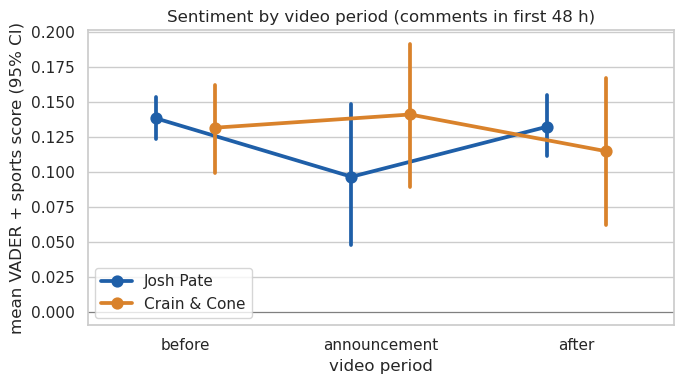

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.pointplot(data=first48, x="period", y=SCORE, hue="creator_name", order=PERIOD_ORDER,
              palette=CREATOR_COLORS, dodge=0.3, errorbar=("ci", 95), ax=ax)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="video period", ylabel=f"mean {SCORE_NAME} score (95% CI)",
       title=f"Sentiment by video period (comments in first {WINDOW_H} h)")
ax.legend(title=None)
save(fig, "05_period_means.png")

### Same show, one week apart: pair 1 (rankings before) vs pair 4 (rankings after)

In [7]:
pair14 = first48[first48["topic_pair"].isin(["1_cfp_rankings_pre", "4_cfp_rankings_post"])]
pair_tests = pd.DataFrame({
    name: compare(g.loc[g["topic_pair"] == "1_cfp_rankings_pre", SCORE],
                  g.loc[g["topic_pair"] == "4_cfp_rankings_post", SCORE])
    for name, g in pair14.groupby("creator_name")}).T
pair_tests.columns = ["n_pair1", "n_pair4", "mean_pair1", "mean_pair4", "diff", "cohens_d", "p_welch", "p_mannwhitney"]
pair_tests.round(3)

,n_pair1,n_pair4,mean_pair1,mean_pair4,diff,cohens_d,p_welch,p_mannwhitney
Crain & Cone,502.0,274.0,0.057,0.126,0.069,0.125,0.101,0.092
Josh Pate,1755.0,2036.0,0.122,0.118,-0.004,-0.007,0.820,0.931


## Level 2: within-video split at the announcement

Only videos published before the announcement that have comments on **both** sides of it: the two pair-2 videos and the 8 supplement videos. The pair-1 videos are left out: they were published 5½ days earlier, so every comment they have after the announcement was removed by the 72-hour outdated rule in notebook 02.

In [8]:
pre = df[df["video_published_utc"] < config.ANNOUNCE_UTC].copy()
both_sides = pre.groupby("video_id")["after_announce"].nunique() == 2
pre = pre[pre["video_id"].isin(both_sides[both_sides].index)]
pre["split"] = np.where(pre["after_announce"], "after", "before")
print(f"{len(pre):,} comments on {pre['video_id'].nunique()} pre-announcement videos")

level2 = pd.DataFrame({
    name: compare(g.loc[~g["after_announce"], SCORE], g.loc[g["after_announce"], SCORE])
    for name, g in [("All", pre), *pre.groupby("creator_name")]}).T
level2.columns = ["n_before", "n_after", "mean_before", "mean_after", "diff", "cohens_d", "p_welch", "p_mannwhitney"]
level2.round(3)

3,479 comments on 10 pre-announcement videos


,n_before,n_after,mean_before,mean_after,diff,cohens_d,p_welch,p_mannwhitney
All,2266.0,1213.0,0.158,0.157,-0.001,-0.002,0.965,0.993
Crain & Cone,426.0,229.0,0.184,0.220,0.036,0.072,0.386,0.348
Josh Pate,1840.0,984.0,0.152,0.142,-0.009,-0.019,0.641,0.653


In [9]:
labels = (pre.groupby(["creator_name", "split"])[LABEL].value_counts(normalize=True)
          .unstack()[LABEL_ORDER].reindex(["before", "after"], level="split").round(3))
print(f"{SCORE_NAME} label shares:")
display(labels)

for name, g in pre.groupby("creator_name"):
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(g["split"], g[LABEL]))
    print(f"{name}: chi-square = {chi2:.2f}, df = {dof}, p = {p:.3f}")

VADER + sports label shares:


vader_sports_label   negative  neutral  positive
creator_name split                              
Crain & Cone before     0.249    0.235     0.516
             after      0.245    0.179     0.576
Josh Pate    before     0.283    0.203     0.515
             after      0.313    0.186     0.501

Crain & Cone: chi-square = 3.16, df = 2, p = 0.206
Josh Pate: chi-square = 3.17, df = 2, p = 0.205


In [10]:
per_video = (pre.groupby(["creator_name", "video_id", "split"])[SCORE].agg(["size", "mean"])
             .unstack("split").fillna(0))
per_video.columns = [f"{a}_{b}" for a, b in per_video.columns]
thin = per_video[(per_video["size_before"] < 10) | (per_video["size_after"] < 10)]
print(f"Left out of this table (fewer than 10 comments on one side): {list(thin.index.get_level_values('video_id'))}")
per_video = per_video.drop(thin.index)
per_video["diff"] = per_video["mean_after"] - per_video["mean_before"]
per_video = per_video.join(df.drop_duplicates("video_id").set_index("video_id")["video_title"].str[:55], on="video_id")
print(f"After minus before is negative in {(per_video['diff'] < 0).sum()} of {len(per_video)} videos")
per_video.round(3).sort_values("diff")

Left out of this table (fewer than 10 comments on one side): ['55sOGgz2RXQ']
After minus before is negative in 4 of 9 videos


size_after  size_before  mean_after  mean_before  \
creator_name video_id                                                        
Josh Pate    0wNBdXIY7mQ         111           16       0.134        0.387   
Crain & Cone r5gPfGKLktQ          60           84       0.138        0.311   
             N3YC5TzxV48          24           27       0.264        0.307   
Josh Pate    Jg42dGYnhtI         365          537       0.102        0.125   
             CRR3qVcpRDY         155          930       0.206        0.174   
             T0TBq5dm5ug          90           49       0.175        0.142   
Crain & Cone DiBaAzFwbrg         117          122       0.229        0.167   
Josh Pate    sI0AWZe9QM4         181          307       0.210        0.121   
Crain & Cone rAqrsZlhTkc          28          193       0.316        0.122   

                           diff  \
creator_name video_id             
Josh Pate    0wNBdXIY7mQ -0.254   
Crain & Cone r5gPfGKLktQ -0.173   
             N3YC5TzxV48 -0.043   
Josh Pate    Jg42dGYnhtI -0.023   
             CRR3qVcpRDY  0.032   
             T0TBq5dm5ug  0.033   
Crain & Cone DiBaAzFwbrg  0.062   
Josh Pate    sI0AWZe9QM4  0.089   
Crain & Cone rAqrsZlhTkc  0.194   

                                                                      video_title  
creator_name video_id                                                              
Josh Pate    0wNBdXIY7mQ  Tennessee BEATS Kentucky...FULL Reaction - Josh Pate's   
Crain & Cone r5gPfGKLktQ         USC vs. Indiana FULL GAME PREVIEW | Crain & Cone  
             N3YC5TzxV48    Missouri vs. Georgia FULL GAME PREVIEW | Crain & Cone  
Josh Pate    Jg42dGYnhtI  CFP & National Championship Predictions...UPDATED - Jos  
             CRR3qVcpRDY  AP Poll Week 11 Reaction...MOST Overrated & Underrated   
             T0TBq5dm5ug  Georgia DESTROYS Ole Miss...FULL Reaction - Josh Pate's  
Crain & Cone DiBaAzFwbrg           Texas vs. LSU FULL GAME PREVIEW | Crain & Cone  
Josh Pate    sI0AWZe9QM4  Notre Dame BEATS Miami...FULL Reaction - Josh Pate's Co  
Crain & Cone rAqrsZlhTkc         College Football Week 11 AP Poll Top-25 REACTION

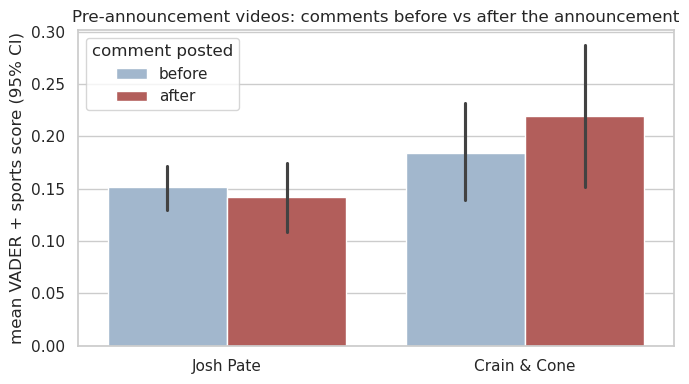

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=pre, x="creator_name", y=SCORE, hue="split", hue_order=["before", "after"],
            palette={"before": "#9bb7d4", "after": "#c0504d"}, errorbar=("ci", 95), ax=ax)
ax.set(xlabel=None, ylabel=f"mean {SCORE_NAME} score (95% CI)",
       title="Pre-announcement videos: comments before vs after the announcement")
ax.legend(title="comment posted")
save(fig, "05_within_video_split.png")

### Regression: controlling for comment age, replies and video

`score ~ after_announce + log(1 + hours since upload) + is_reply + video fixed effects`, with robust (HC1) standard errors. The coefficient on `after_announce` is the shift that is not explained by comments simply being later or being replies.

In [12]:
def event_regression(data, score=SCORE, flag="after_announce"):
    d = data.assign(y=data[score], after=data[flag].astype(int), is_reply=data["is_reply"].astype(int),
                    log_age=np.log1p(data["hours_since_upload"].clip(lower=0)))
    fit = smf.ols("y ~ after + log_age + is_reply + C(video_id)", data=d).fit(cov_type="HC1")
    lo, hi = fit.conf_int().loc["after"]
    return pd.Series({"n": int(fit.nobs), "coef_after": fit.params["after"], "ci_low": lo, "ci_high": hi,
                      "p": fit.pvalues["after"], "coef_log_age": fit.params["log_age"]})

reg = pd.DataFrame({name: event_regression(g) for name, g in [("All", pre), *pre.groupby("creator_name")]}).T
reg.round(3)

,n,coef_after,ci_low,ci_high,p,coef_log_age
All,3479.0,0.019,-0.039,0.078,0.520,-0.004
Crain & Cone,655.0,-0.008,-0.154,0.138,0.914,0.015
Josh Pate,2824.0,0.026,-0.038,0.090,0.425,-0.007


## Sensitivity checks

1. Split at 10:30 CT (`after_announce_alt`) instead of 10:30 ET.
2. Standard VADER without the sports words (`vader_compound`).
3. TextBlob polarity.

In [13]:
rows = []
for label, score, flag in [("main: VADER + sports, 10:30 ET", SCORE, "after_announce"),
                           ("split at 10:30 CT", SCORE, "after_announce_alt"),
                           ("standard VADER", "vader_compound", "after_announce"),
                           ("TextBlob polarity", "tb_polarity", "after_announce")]:
    for name, g in [("All", pre), *pre.groupby("creator_name")]:
        r = event_regression(g, score, flag)
        rows.append({"check": label, "group": name, **r.to_dict()})
sensitivity = pd.DataFrame(rows)
moved = (pre["after_announce"] != pre["after_announce_alt"]).sum()
print(f"Comments that change side between the two split times: {moved}")
sensitivity.pivot(index="check", columns="group", values="coef_after").round(3)

Comments that change side between the two split times: 119


group,All,Crain & Cone,Josh Pate
check,,,
TextBlob polarity,0.026,0.058,0.021
"main: VADER + sports, 10:30 ET",0.019,-0.008,0.026
split at 10:30 CT,-0.005,0.016,-0.007
standard VADER,0.023,0.006,0.028


In [14]:
sensitivity.round(4).to_csv(config.DATA_DIR / "event_study_results.csv", index=False)
print("saved data/event_study_results.csv")

saved data/event_study_results.csv


## Time series

All comments in 6-hour bins of real time, relative to the announcement. The bars show volume, the line shows the mean VADER + sports score (bins with at least 20 comments).

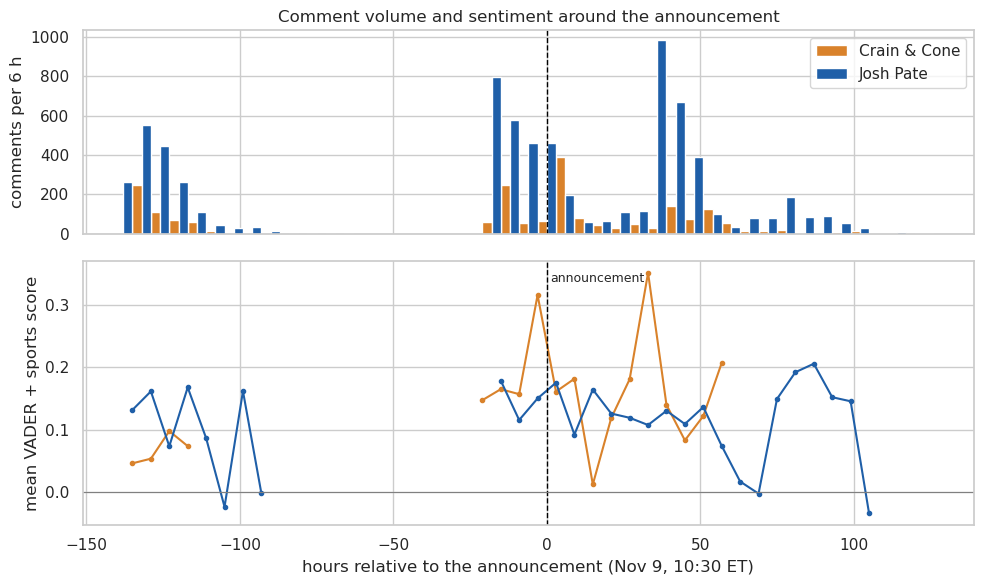

In [15]:
BIN_H = 6
df["bin"] = np.floor(df["hours_vs_announce"] / BIN_H) * BIN_H
ts = df.groupby(["creator_name", "bin"])[SCORE].agg(["size", "mean"]).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
for name, g in ts.groupby("creator_name"):
    axes[0].bar(g["bin"] + (0 if name == "Josh Pate" else BIN_H / 2), g["size"], width=BIN_H / 2,
                color=CREATOR_COLORS[name], label=name, align="edge")
    # put every bin on a full grid so that gaps and thin bins (< 20 comments) break the line
    grid = np.arange(ts["bin"].min(), ts["bin"].max() + BIN_H, BIN_H)
    ok = g.set_index("bin").reindex(grid)
    ok.loc[ok["size"].fillna(0) < 20, "mean"] = np.nan
    axes[1].plot(grid + BIN_H / 2, ok["mean"], marker="o", ms=3, color=CREATOR_COLORS[name], label=name)
for ax in axes:
    ax.axvline(0, color="black", ls="--", lw=1)
axes[0].set(ylabel=f"comments per {BIN_H} h", title="Comment volume and sentiment around the announcement")
axes[1].set(ylabel=f"mean {SCORE_NAME} score", xlabel="hours relative to the announcement (Nov 9, 10:30 ET)")
axes[1].axhline(0, color="grey", lw=0.8)
axes[0].legend()
axes[1].text(1, axes[1].get_ylim()[1] * 0.95, "announcement", va="top", fontsize=9)
save(fig, "05_time_series.png")

### Event window on pre-announcement videos only (±48 h)

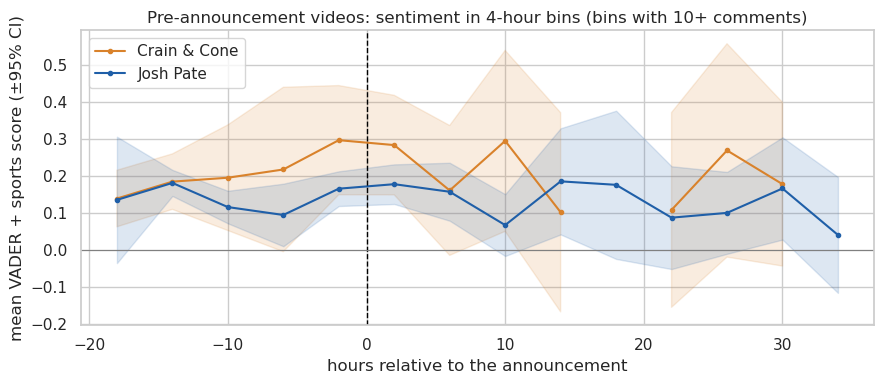

In [16]:
win = pre[pre["hours_vs_announce"].between(-48, 48)].copy()
win["bin"] = np.floor(win["hours_vs_announce"] / 4) * 4
w = win.groupby(["creator_name", "bin"])[SCORE].agg(["size", "mean", "sem"]).reset_index()
w = (w.set_index(["creator_name", "bin"])
       .reindex(pd.MultiIndex.from_product([w["creator_name"].unique(), np.arange(-48, 48, 4)], names=["creator_name", "bin"]))
       .reset_index())
w.loc[w["size"].fillna(0) < 10, ["mean", "sem"]] = np.nan      # thin or empty bins break the line

fig, ax = plt.subplots(figsize=(9, 4))
for name, g in w.groupby("creator_name"):
    x = g["bin"] + 2
    ax.plot(x, g["mean"], marker="o", ms=3, color=CREATOR_COLORS[name], label=name)
    ax.fill_between(x, g["mean"] - 1.96 * g["sem"], g["mean"] + 1.96 * g["sem"], color=CREATOR_COLORS[name], alpha=0.15)
ax.axvline(0, color="black", ls="--", lw=1)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="hours relative to the announcement", ylabel=f"mean {SCORE_NAME} score (±95% CI)",
       title="Pre-announcement videos: sentiment in 4-hour bins (bins with 10+ comments)")
ax.legend()
save(fig, "05_event_window.png")

In [17]:
print("Comments in the ±48 h window by side:")
win.groupby(["creator_name", "after_announce"]).size().unstack().rename(columns={False: "before", True: "after"})

Comments in the ±48 h window by side:


after_announce,before,after
creator_name,,
Crain & Cone,426,198
Josh Pate,1840,961
